# FiQA Dataset: Exploratory Data Analysis

Inspect the BEIR FiQA corpus, queries, and official train/dev/test relevance judgments. This notebook does not alter benchmark splits or create negatives. Unjudged query-document pairs are unknown, not confirmed negatives.

Datasets: [BeIR/fiqa](https://huggingface.co/datasets/BeIR/fiqa) and [BeIR/fiqa-qrels](https://huggingface.co/datasets/BeIR/fiqa-qrels). Both dataset cards list CC BY-SA 4.0.

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
from datasets import load_dataset

DATASET_ID = 'BeIR/fiqa'
DATASET_REVISION = '979c07a'  # reviewed HF snapshot
QRELS_DATASET_ID = 'BeIR/fiqa-qrels'
QRELS_REVISION = '252958f'  # reviewed HF snapshot

## Load corpus and queries

Both configs use `_id`, `title`, and `text`. We inspect the actual loaded counts rather than assuming metadata is correct.

In [11]:
corpus = load_dataset(DATASET_ID, 'corpus', split='corpus', revision=DATASET_REVISION).to_pandas()
queries = load_dataset(DATASET_ID, 'queries', split='queries', revision=DATASET_REVISION).to_pandas()
print('Corpus:', corpus.shape, corpus.dtypes.to_dict())
print('Queries:', queries.shape, queries.dtypes.to_dict())
display(corpus.head(3), queries.head(3))

Corpus: (57638, 3) {'_id': <StringDtype(na_value=nan)>, 'title': <StringDtype(na_value=nan)>, 'text': <StringDtype(na_value=nan)>}
Queries: (6648, 3) {'_id': <StringDtype(na_value=nan)>, 'title': <StringDtype(na_value=nan)>, 'text': <StringDtype(na_value=nan)>}


,_id,title,text
0,3,,I'm not saying I don't like the idea of on-the...
1,31,,So nothing preventing false ratings besides ad...
2,56,,You can never use a health FSA for individual ...


,_id,title,text
0,0,,What is considered a business expense on a bus...
1,4,,Business Expense - Car Insurance Deductible Fo...
2,5,,Starting a new online business


In [12]:
expected = {'_id', 'title', 'text'}
for name, frame in [('corpus', corpus), ('queries', queries)]:
    assert expected <= set(frame.columns), f'{name} schema: {frame.columns.tolist()}'
    print(f'{name}: rows={len(frame):,}; duplicate IDs={frame._id.duplicated().sum():,}')
    display(frame[list(expected)].isna().sum().rename(f'{name} null counts'))
print('Corpus/query ID overlap:', len(set(corpus._id) & set(queries._id)))

corpus: rows=57,638; duplicate IDs=0


title    0
text     0
_id      0
Name: corpus null counts, dtype: int64

queries: rows=6,648; duplicate IDs=0


title    0
text     0
_id      0
Name: queries null counts, dtype: int64

Corpus/query ID overlap: 621


## Text length and duplicate checks

Word counts are rough diagnostics, not tokenizer lengths. They do not determine model truncation settings.

In [13]:
def with_text_stats(frame):
    out = frame.copy()
    out['combined'] = (out.title.fillna('').astype(str) + ' ' + out.text.fillna('').astype(str)).str.strip()
    out['word_count'] = out.combined.str.split().str.len()
    return out

corpus_stats, query_stats = with_text_stats(corpus), with_text_stats(queries)
display(pd.DataFrame({'corpus_words': corpus_stats.word_count.describe(percentiles=[.5,.9,.95,.99]),
                      'query_words': query_stats.word_count.describe(percentiles=[.5,.9,.95,.99])}))
print('Empty texts (corpus, queries):', (corpus_stats.word_count == 0).sum(), (query_stats.word_count == 0).sum())
for name, frame in [('corpus', corpus_stats), ('queries', query_stats)]:
    dup = frame.combined.duplicated(keep=False)
    print(f'{name}: rows in exact duplicate text groups={dup.sum():,}')
    display(frame.loc[dup, ['_id','title','text']].head(5))

,corpus_words,query_words
count,57638.000000,6648.000000
mean,132.904473,10.822052
std,128.738342,4.387923
min,0.000000,2.000000
50%,90.000000,10.000000
90%,270.000000,17.000000
95%,368.000000,19.000000
99%,641.630000,23.000000
max,2973.000000,31.000000


Empty texts (corpus, queries): 38 0
corpus: rows in exact duplicate text groups=42


,_id,title,text
741,7915,,
1158,12229,,
1329,14135,,
3208,33445,,
3937,40982,,


queries: rows in exact duplicate text groups=0


,_id,title,text


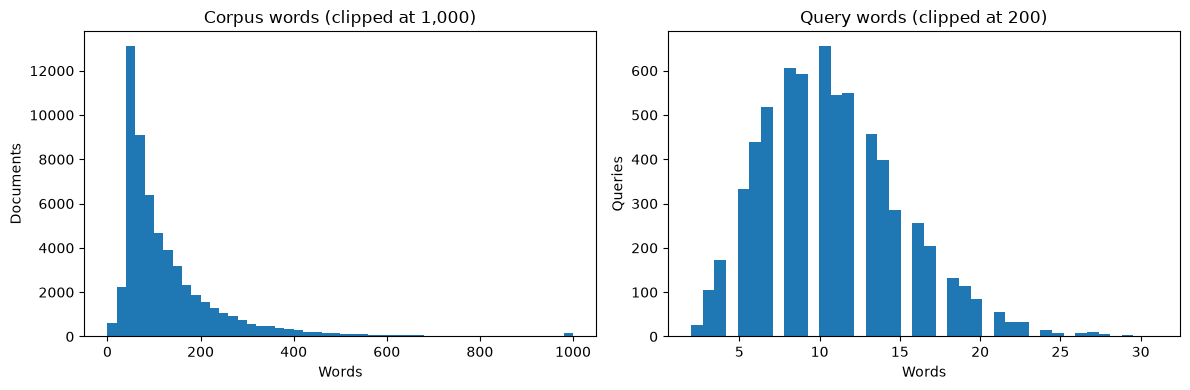

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(corpus_stats.word_count.clip(upper=1000), bins=50)
axes[0].set(title='Corpus words (clipped at 1,000)', xlabel='Words', ylabel='Documents')
axes[1].hist(query_stats.word_count.clip(upper=200), bins=40)
axes[1].set(title='Query words (clipped at 200)', xlabel='Words', ylabel='Queries')
plt.tight_layout()

## Load official qrels from Hugging Face

The qrels are loaded directly from the `BeIR/fiqa-qrels` dataset. Keep its official train, dev, and test splits intact.

In [15]:
# HF Datasets exposes the canonical dev.tsv file under the conventional `validation` split name.
QRELS_SPLIT_NAMES = {'train': 'train', 'dev': 'validation', 'test': 'test'}
qrels_by_split = {
    canonical_split: load_dataset(QRELS_DATASET_ID, split=hf_split, revision=QRELS_REVISION).to_pandas()
    for canonical_split, hf_split in QRELS_SPLIT_NAMES.items()
}

for split, qrels in qrels_by_split.items():
    print(split, qrels.shape, qrels.dtypes.to_dict())
    display(qrels.head(3))

train (14166, 3) {'query-id': dtype('int64'), 'corpus-id': dtype('int64'), 'score': dtype('int64')}


,query-id,corpus-id,score
0,0,18850,1
1,4,196463,1
2,5,69306,1


dev (1238, 3) {'query-id': dtype('int64'), 'corpus-id': dtype('int64'), 'score': dtype('int64')}


,query-id,corpus-id,score
0,1,14255,1
1,2,308938,1
2,3,296717,1


test (1706, 3) {'query-id': dtype('int64'), 'corpus-id': dtype('int64'), 'score': dtype('int64')}


,query-id,corpus-id,score
0,8,566392,1
1,8,65404,1
2,15,325273,1


In [16]:
def normalize_qrels(frame):
    expected = {'query-id', 'corpus-id', 'score'}
    if set(frame.columns) != expected:
        raise ValueError(f'Unexpected qrels schema: {frame.columns.tolist()}')
    frame = frame.rename(columns={'query-id':'query_id', 'corpus-id':'doc_id'}).copy()
    frame['query_id'] = frame['query_id'].astype(str)
    frame['doc_id'] = frame['doc_id'].astype(str)
    return frame

qrels_by_split = {name: normalize_qrels(frame) for name, frame in qrels_by_split.items()}
query_ids, doc_ids = set(queries._id), set(corpus._id)
for split, qrels in sorted(qrels_by_split.items()):
    q_overlap = set(qrels.query_id) & query_ids
    d_overlap = set(qrels.doc_id) & doc_ids
    positive = qrels[qrels.score > 0]
    per_query = positive.groupby('query_id').doc_id.nunique()
    print(f'{split}: judgments={len(qrels):,}; queries={qrels.query_id.nunique():,}; docs={qrels.doc_id.nunique():,}')
    print(f'  qrels IDs found in HF data: queries {len(q_overlap):,}/{qrels.query_id.nunique():,}; docs {len(d_overlap):,}/{qrels.doc_id.nunique():,}')
    print('  scores:', qrels.score.value_counts().sort_index().to_dict())
    print('  positive judgments/query median:', per_query.median())
    assert q_overlap == set(qrels.query_id), f'{split}: missing query IDs'
    assert d_overlap == set(qrels.doc_id), f'{split}: missing corpus IDs'

dev: judgments=1,238; queries=500; docs=1,238
  qrels IDs found in HF data: queries 500/500; docs 1,238/1,238
  scores: {1: 1238}
  positive judgments/query median: 2.0
test: judgments=1,706; queries=648; docs=1,706
  qrels IDs found in HF data: queries 648/648; docs 1,706/1,706
  scores: {1: 1706}
  positive judgments/query median: 2.0
train: judgments=14,166; queries=5,500; docs=14,166
  qrels IDs found in HF data: queries 5,500/5,500; docs 14,166/14,166
  scores: {1: 14166}
  positive judgments/query median: 2.0


## Split integrity and interpretation

Queries should be disjoint between official qrels splits. The corpus is shared across retrieval splits by design, so document reuse across queries is not itself leakage. Qrels record judgments only; absence of a pair from qrels does not mean it is irrelevant. Reserve test judgments for final evaluation, never tuning.

In [17]:
split_queries = {name: set(frame.query_id) for name, frame in qrels_by_split.items()}
names = sorted(split_queries)
for i, left in enumerate(names):
    for right in names[i+1:]:
        overlap = split_queries[left] & split_queries[right]
        print(f'{left}/{right} query overlap: {len(overlap)}')
        assert not overlap, f'Query leakage between {left} and {right}'
print('Keep unjudged pairs unknown; do not label them confirmed negatives.')

dev/test query overlap: 0
dev/train query overlap: 0
test/train query overlap: 0
Keep unjudged pairs unknown; do not label them confirmed negatives.


## Notes for the experiment report

Record the observed row counts, duplicate findings, qrels counts, and dataset revision. Confirm the results against the dataset card and canonical BEIR files before training.